In [1]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display


In [2]:

from sklearn.datasets import make_classification
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

X, y = make_classification(
    n_samples=100,
    n_features=2,
    n_informative=1,
    n_redundant=0,
    n_classes=2,
    n_clusters_per_class=1,
    random_state=41,
    hypercube=False,
    class_sep=10
)


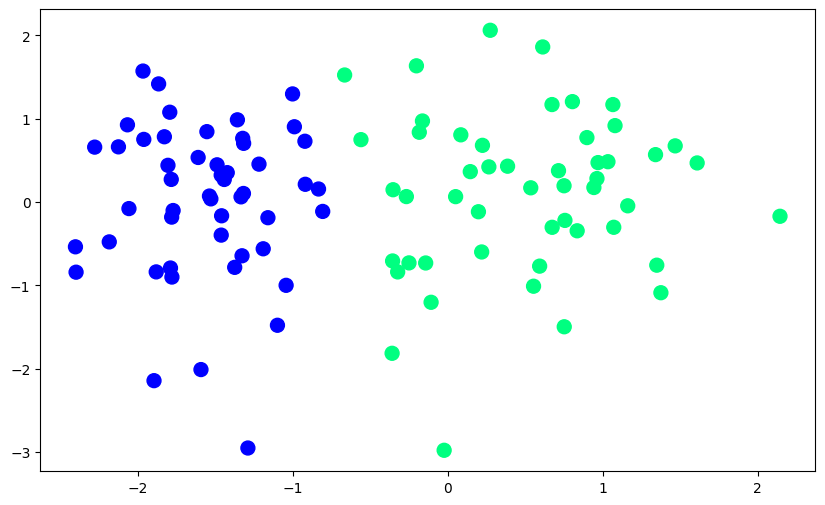

In [3]:

plt.figure(figsize=(10, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='winter', s=100)
plt.show()



In [4]:

def step(z):
    return 1 if z > 0 else 0


def perceptron(X, y):
    X = np.insert(X, 0, 1, axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1

    for i in range(1000):
        j = np.random.randint(0, len(X))
        y_hat = step(np.dot(X[j], weights))
        weights = weights + lr * (y[j] - y_hat) * X[j]

    return weights[0], weights[1:]


In [5]:

intercept_, coef_ = perceptron(X, y)

print("Coefficients:", coef_)
print("Intercept:", intercept_)


Coefficients: [1.3337247  0.05189685]
Intercept: 1.0


In [6]:

m = -(coef_[0] / coef_[1])
b = -(intercept_ / coef_[1])

print("Slope:", m)
print("Intercept:", b)


Slope: -25.699532322520575
Intercept: -19.268993340375513


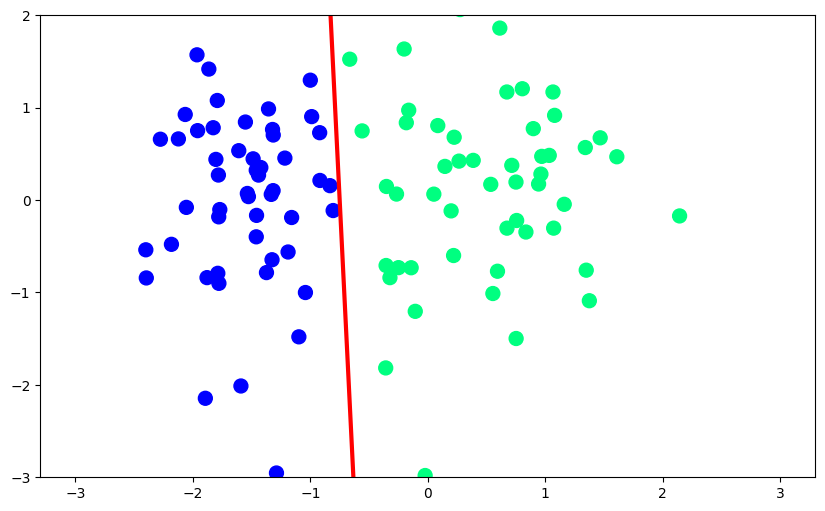

In [7]:

x_input = np.linspace(-3, 3, 100)
y_input = m * x_input + b

plt.figure(figsize=(10, 6))
plt.plot(x_input, y_input, color='red', linewidth=3)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='winter', s=100)
plt.ylim(-3, 2)
plt.show()


In [8]:

def step(z):
    return 1 if z > 0 else 0


def perceptron(X, y):
    X = np.insert(X, 0, 1, axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1
    weights_history = []

    for i in range(1000):
        j = np.random.randint(0, len(X))
        y_hat = step(np.dot(X[j], weights))

        weights = weights + lr * (y[j] - y_hat) * X[j]

        weights_history.append(weights.copy())

    return weights[0], weights[1:], np.array(weights_history)


In [9]:

intercept_, coef_, weights_history = perceptron(X, y)

print("Weights history shape:", weights_history.shape)
print("First weights:", weights_history[0])
print("Last weights:", weights_history[-1])


Weights history shape: (1000, 3)
First weights: [0.9        1.17920701 0.89221795]
Last weights: [1.         1.38433608 0.03393636]


In [10]:

m_history = -weights_history[:, 1] / weights_history[:, 2]
b_history = -weights_history[:, 0] / weights_history[:, 2]

print("Slope history:", m_history.shape)
print("Intercept history:", b_history.shape)


Slope history: (1000,)
Intercept history: (1000,)


In [12]:

fig, ax = plt.subplots(figsize=(9, 5))

x_i = np.arange(-3, 3, 0.1)

ax.scatter(X[:, 0], X[:, 1], c=y, cmap='winter', s=100)

line, = ax.plot(
    x_i,
    m_history[0] * x_i + b_history[0],
    'r-',
    linewidth=2
)

ax.set_ylim(-3, 3)

def update(i):
    line.set_ydata(m_history[i] * x_i + b_history[i])
    ax.set_xlabel(f'Epoch {i + 1}')
    return line,

anim = FuncAnimation(
    fig,
    update,
    frames=250,
    interval=30,
    blit=False,
    repeat=True
)

plt.close(fig)
display(HTML(anim.to_jshtml()))
